# Assignment: Generative Adversarial Network (GAN) {-}

This assignment aims at familiarizing you with training, validating and testing a Generative Adversarial Network (GAN). Here are the requirements of the assignment:

1.  **(5 points) Coding Tasks:** The following questions involve writing code to complete specific tasks.  
    1.1 *(1 point)* Load and process the dataset. To save training time, you only need to load and work on ONE image class of your choice.  
    1.2 *(2 points)* Build a GAN architecture consisting of at least one (01) Discriminator and one (01) Generator of which the architectures are of your choice. You are encouraged to customize the network architectures to be different from the ones demonstrated in the demo code. There are two levels of image generation requirements:
    - First-level requirement: train and generate images for ONE class of the dataset using vanilla GAN. You are free to choose which class of object you are interested in working on.
    - Second-level requirement: train and generate images for ONE class of the dataset using the mechanism of ProGAN. While strict adherence to the original paper's architecture is optional, you must maintain the core progressive training strategy (growing from low to high resolution).    

    1.3 *(1 point)* Visualize the model behaviors during the training and the validation.  
    1.4 *(1 point)* Visualize the generated images.    

2.  **(5 points) Open discussion questions:** These discussion questions ask you to analyze and argue your points.  Feel free to include relevant code examples to strengthen your arguments.  
    2.1 *(1 point)* Explain the architecture of your Generator and Discriminator. What specific layers or structures did you include, and why did you choose them?  
    2.2 *(1 point)* How does the architecture of your vanilla GAN differ from the light version of ProGAN? What changes did you make to implement the ProGAN structure?  
    2.3 *(1 point)* When working on the ProGAN, what specific issues did you face that differed from training the vanilla GAN? Did the training process improve or worsen with ProGAN?   
    2.4 *(1 point)* How did hyperparameters (e.g., learning rate, batch size) influence the performance of your GAN? Did you adjust them during training to improve results?  
    2.5 *(1 point)* What improvements would you make to your GAN or ProGAN implementation? Would you add any additional techniques or layers to improve the image generation quality?  

The dataset you will be working on is CIFAR-10. This dataset consists of 60,000 32x32 colour images in 10 classes, with 6,000 images per class. There are 50,000 training images and 10,000 test images.

Here follows some data samples in the dataset:

![alt text](https://github.com/mintus2511/ADL_230167_Assignment3/blob/main/cifar10.png?raw=1)

### Submission {-}
The structure of submission folder should be organized as follows:

- ./\<StudentID>-assignment-GAN-notebook.ipynb: Jupyter notebook containing source code.

The submission folder is named ADL-\<StudentID>-Assignment-GAN (e.g., ADL-2012345-Assigment-GAN) and then compressed with the same name.

### Evaluation {-}
Assignment evaluation will be conducted on how you accomplish the assignment requirements. It is a plus if you have modeling steps other than the basic requirements and achieve an excellent model performance. In addition, your code should conform to a Python coding convention such as PEP-8.

### Deadline {-}
Please visit Canvas for details.

In [1]:
# Note: to enable GPU training in Colab, go to Runtime > Change runtime type > Hardware acceleration > Choose GPU from the drop-down list.

!pip install tensorflow_datasets
!pip install importlib-resources

# Import libraries
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
from keras import callbacks
from keras import optimizers
from keras.datasets import cifar10
from keras.layers import Dropout, Flatten, Dense, BatchNormalization
from keras import Model
from datasets import load_dataset

from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt

# First-level requirement
First-level requirement: train and generate images for ONE class of the dataset using vanilla GAN. You are free to choose which class of object you are interested in working on.

In [2]:
# 1. Load dataset from the Hugging Face UofT mirror
ds = load_dataset("uoft-cs/cifar10")

# 2. Helper function to convert Hugging Face split into NumPy arrays
def dataset_to_numpy(split):
    # Convert PIL images to NumPy arrays
    images = np.array([np.array(img) for img in split["img"]])
    labels = np.array(split["label"])
    return images, labels

X_train, y_train = dataset_to_numpy(ds["train"])
X_test, y_test = dataset_to_numpy(ds["test"])

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

# 3. Build TensorFlow tf.data.Dataset pipelines
batch_size = 64

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=10000)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000,)


In [3]:
# Get samples  of a certain label
label = 1 # Class '1' is car. You may change this label to another class label.
train_indices = np.where(y_train == label) # Get indices of the label
train_set = X_train[train_indices] # Get train samples of the label
test_indices = np.where(y_test == label) # Get indices of the label
test_set = X_train[test_indices] # Get test samples of the label

# Print shapes of datasets of the selected class
print("train_set shape of the selected class: " + str(train_set.shape))
print("test_set shape of the selected class: " + str(test_set.shape))

# NOTE: training a GAN does not require to have train/test split. All data samples of the training and the test set are used as real data samples.
# You should merge the training and the test set to get more real data samples, i.e., merge the train_set and the test_set to one dataset which is the real dataset.

train_set shape of the selected class: (5000, 32, 32, 3)
test_set shape of the selected class: (1000, 32, 32, 3)


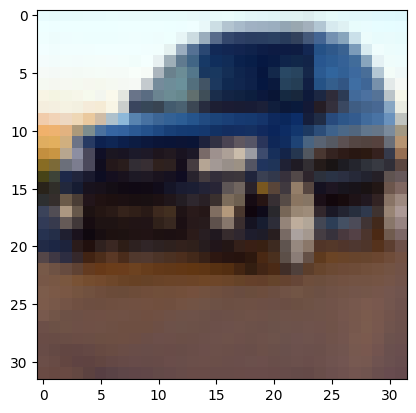

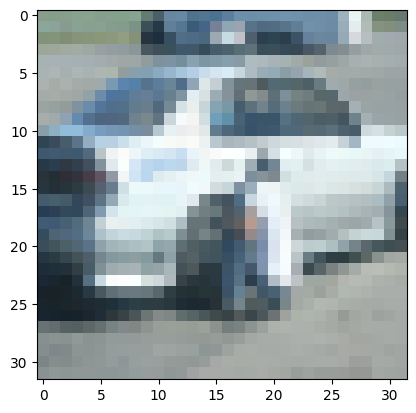

In [4]:
# Visualize some data samples of class '1' (car)
import matplotlib.pyplot as plt
imgplot = plt.imshow(train_set[0])
plt.show()
imgplot = plt.imshow(train_set[1])
plt.show()

## 1. Coding tasks

# **1.1 - Process the selected CIFAR-10 class**

In [14]:
# Merge the training and test samples of the selected class
real_dataset = np.concatenate((train_set, test_set), axis=0)

# Convert pixel values to float32
real_dataset = real_dataset.astype("float32")

# Normalize pixel values from [0, 255] to [0, 1]
real_dataset = real_dataset / 255.0

# Check the processed dataset
print("Real dataset shape:", real_dataset.shape)
print("Data type:", real_dataset.dtype)
print("Minimum pixel value:", real_dataset.min())
print("Maximum pixel value:", real_dataset.max())

Real dataset shape: (6000, 32, 32, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


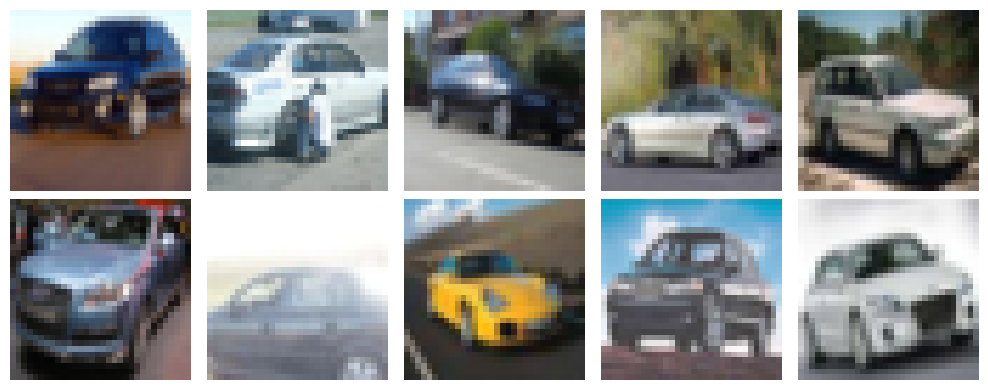

In [15]:
# Visualize processed samples
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(real_dataset[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

### **1.1 Dataset Loading and Preprocessing**

For this assignment, the **automobile** class from CIFAR-10 was selected for GAN training.

After selecting the samples belonging to this class, the training and test images were combined into a single dataset containing:

- **6,000 images**
- Image size: **32 × 32**
- Number of channels: **3 (RGB)**

The resulting dataset has the shape:

`(6000, 32, 32, 3)`

The pixel values were converted to `float32` and normalized from the original range `[0, 255]` to `[0, 1]`. After preprocessing, the minimum and maximum pixel values were:

- **Minimum:** 0.0
- **Maximum:** 1.0

The visualization of sample images confirms that the selected dataset contains automobile images and that the image structure and color information were preserved after preprocessing.

This processed dataset will be used as the real-image distribution for training the GAN.

# **1.2 - Vanilla GAN**

In [16]:
from keras.models import Sequential
from keras.layers import (
    Conv2D,
    Conv2DTranspose,
    Reshape,
    LeakyReLU,
    Input
)

latent_dim = 128
image_shape = (32, 32, 3)

In [17]:
def define_generator(latent_dim=128):
    model = Sequential(name="Vanilla_Generator")

    # Convert the latent vector into a small 4x4 feature map
    model.add(Input(shape=(latent_dim,)))
    model.add(Dense(4 * 4 * 256))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Reshape((4, 4, 256)))

    # 4x4 -> 8x8
    model.add(
        Conv2DTranspose(
            128,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))

    # 8x8 -> 16x16
    model.add(
        Conv2DTranspose(
            64,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))

    # 16x16 -> 32x32
    model.add(
        Conv2DTranspose(
            32,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(LeakyReLU(negative_slope=0.2))

    # Generate a 32x32 RGB image
    model.add(
        Conv2D(
            3,
            kernel_size=3,
            padding="same",
            activation="sigmoid"
        )
    )

    return model

In [18]:
def define_discriminator(in_shape=(32, 32, 3)):
    model = Sequential(name="Vanilla_Discriminator")

    model.add(Input(shape=in_shape))

    # 32x32 -> 16x16
    model.add(
        Conv2D(
            64,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dropout(0.3))

    # 16x16 -> 8x8
    model.add(
        Conv2D(
            128,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dropout(0.3))

    # 8x8 -> 4x4
    model.add(
        Conv2D(
            256,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dropout(0.3))

    model.add(Flatten())

    # Probability that the image is real
    model.add(Dense(1, activation="sigmoid"))

    return model

In [19]:
g_model = define_generator(latent_dim)
d_model = define_discriminator(image_shape)

print("Generator summary:")
g_model.summary()

print("\nDiscriminator summary:")
d_model.summary()

Generator summary:


Model: "Vanilla_Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4096)           │       528,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,218,499 (4.65 MB)

 Trainable params: 1,218,051 (4.65 MB)

 Non-trainable params: 448 (1.75 KB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 662,977 (2.53 MB)

 Trainable params: 662,977 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Test the generator with one random latent vector
test_noise = np.random.randn(1, latent_dim).astype("float32")
test_image = g_model.predict(test_noise, verbose=0)

print("Generated image shape:", test_image.shape)
print("Minimum generated value:", test_image.min())
print("Maximum generated value:", test_image.max())

Generated image shape: (1, 32, 32, 3)
Minimum generated value: 0.48525462
Maximum generated value: 0.5147375


#### **Vanilla GAN Architecture**

The Vanilla GAN consists of a Generator and a Discriminator designed for the selected CIFAR-10 automobile images.

The **Generator** takes a 128-dimensional latent vector and progressively increases its spatial resolution through transposed convolution layers:

`128-D → 4×4×256 → 8×8×128 → 16×16×64 → 32×32×32 → 32×32×3`

The final layer uses a sigmoid activation so that the generated RGB pixel values are in the same `[0, 1]` range as the preprocessed real images.

The Generator contains approximately **1.22 million parameters**.

The **Discriminator** performs the reverse operation. It progressively reduces the spatial resolution while increasing the number of feature channels:

`32×32×3 → 16×16×64 → 8×8×128 → 4×4×256 → 1`

LeakyReLU activations are used after the convolution layers, while Dropout is included to reduce overfitting. The final sigmoid output represents the probability that an input image is real.

The Discriminator contains approximately **663 thousand parameters**.

A test using a randomly sampled latent vector produced an output with shape `(1, 32, 32, 3)`, confirming that the Generator produces images with the correct CIFAR-10 dimensions. Before training, the generated pixel values were concentrated around 0.5, which is expected because the Generator weights are still randomly initialized.

In [21]:
# Compile the discriminator
d_model.trainable = True

d_model.compile(
    loss="binary_crossentropy",
    optimizer=optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.5
    ),
    metrics=["accuracy"]
)


# Build the combined GAN
def define_gan(g_model, d_model):
    # Freeze the discriminator while training the generator
    d_model.trainable = False

    model = Sequential(name="Vanilla_GAN")
    model.add(g_model)
    model.add(d_model)

    model.compile(
        loss="binary_crossentropy",
        optimizer=optimizers.Adam(
            learning_rate=0.0002,
            beta_1=0.5
        )
    )

    return model


gan_model = define_gan(g_model, d_model)

print("Combined GAN summary:")
gan_model.summary()

Combined GAN summary:


Model: "Vanilla_GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Vanilla_Generator (Sequential)  │ (None, 32, 32, 3)      │     1,218,499 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Vanilla_Discriminator           │ (None, 1)              │       662,977 │
│ (Sequential)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,881,476 (7.18 MB)

 Trainable params: 1,218,051 (4.65 MB)

 Non-trainable params: 663,425 (2.53 MB)

In [22]:
# Select a random batch of real images
def generate_real_samples(dataset, n_samples):
    indices = np.random.randint(
        0,
        dataset.shape[0],
        n_samples
    )

    images = dataset[indices]

    # Real images have label 1
    labels = np.ones((n_samples, 1))

    return images, labels


# Generate random latent vectors
def generate_latent_points(latent_dim, n_samples):
    latent_points = np.random.randn(
        n_samples,
        latent_dim
    ).astype("float32")

    return latent_points


# Generate fake images using the Generator
def generate_fake_samples(
    g_model,
    latent_dim,
    n_samples
):
    latent_points = generate_latent_points(
        latent_dim,
        n_samples
    )

    images = g_model.predict(
        latent_points,
        verbose=0
    )

    # Fake images have label 0
    labels = np.zeros((n_samples, 1))

    return images, labels

In [23]:
# Test the real and fake sample functions
real_x, real_y = generate_real_samples(
    real_dataset,
    4
)

fake_x, fake_y = generate_fake_samples(
    g_model,
    latent_dim,
    4
)

print("Real image batch shape:", real_x.shape)
print("Real label shape:", real_y.shape)

print("Fake image batch shape:", fake_x.shape)
print("Fake label shape:", fake_y.shape)

print("Real labels:", real_y.flatten())
print("Fake labels:", fake_y.flatten())

Real image batch shape: (4, 32, 32, 3)
Real label shape: (4, 1)
Fake image batch shape: (4, 32, 32, 3)
Fake label shape: (4, 1)
Real labels: [1. 1. 1. 1.]
Fake labels: [0. 0. 0. 0.]


In [24]:
# Train the Vanilla GAN
def train_vanilla_gan(
    g_model,
    d_model,
    gan_model,
    dataset,
    latent_dim,
    n_epochs=50,
    n_batch=64
):
    half_batch = n_batch // 2
    batches_per_epoch = dataset.shape[0] // n_batch

    d_losses = []
    g_losses = []
    d_accuracies = []

    # Use the same latent vectors to compare image quality over time
    fixed_noise = generate_latent_points(
        latent_dim,
        100
    )

    generated_images = {}

    for epoch in range(n_epochs):
        epoch_d_losses = []
        epoch_g_losses = []
        epoch_d_accs = []

        for _ in range(batches_per_epoch):

            # -------------------------
            # Train the Discriminator
            # -------------------------
            d_model.trainable = True

            real_x, real_y = generate_real_samples(
                dataset,
                half_batch
            )

            d_loss_real, d_acc_real = d_model.train_on_batch(
                real_x,
                real_y
            )

            fake_x, fake_y = generate_fake_samples(
                g_model,
                latent_dim,
                half_batch
            )

            d_loss_fake, d_acc_fake = d_model.train_on_batch(
                fake_x,
                fake_y
            )

            d_loss = 0.5 * (
                float(d_loss_real) +
                float(d_loss_fake)
            )

            d_acc = 0.5 * (
                float(d_acc_real) +
                float(d_acc_fake)
            )

            # -------------------------
            # Train the Generator
            # -------------------------
            d_model.trainable = False

            latent_x = generate_latent_points(
                latent_dim,
                n_batch
            )

            # Generator wants fake images to be classified as real
            misleading_labels = np.ones(
                (n_batch, 1)
            )

            g_loss = gan_model.train_on_batch(
                latent_x,
                misleading_labels
            )

            # Convert possible array/list output to a scalar
            if isinstance(g_loss, (list, tuple)):
                g_loss = g_loss[0]

            g_loss = float(g_loss)

            epoch_d_losses.append(d_loss)
            epoch_g_losses.append(g_loss)
            epoch_d_accs.append(d_acc)

        # Average metrics for the epoch
        mean_d_loss = np.mean(epoch_d_losses)
        mean_g_loss = np.mean(epoch_g_losses)
        mean_d_acc = np.mean(epoch_d_accs)

        d_losses.append(mean_d_loss)
        g_losses.append(mean_g_loss)
        d_accuracies.append(mean_d_acc)

        print(
            f"Epoch {epoch + 1:03d}/{n_epochs} | "
            f"D loss: {mean_d_loss:.4f} | "
            f"D acc: {mean_d_acc:.4f} | "
            f"G loss: {mean_g_loss:.4f}"
        )

        # Save generated samples at selected epochs
        if (epoch + 1) % 10 == 0:
            samples = g_model.predict(
                fixed_noise,
                verbose=0
            )

            generated_images[epoch + 1] = samples

    return (
        d_losses,
        g_losses,
        d_accuracies,
        generated_images
    )

In [25]:
vanilla_d_losses, vanilla_g_losses, vanilla_d_accuracies, vanilla_images = (
    train_vanilla_gan(
        g_model,
        d_model,
        gan_model,
        real_dataset,
        latent_dim,
        n_epochs=50,
        n_batch=64
    )
)

Epoch 001/50 | D loss: 0.5675 | D acc: 0.6944 | G loss: 0.3826
Epoch 002/50 | D loss: 0.2391 | D acc: 0.9064 | G loss: 0.1138
Epoch 003/50 | D loss: 0.3136 | D acc: 0.9068 | G loss: 0.2991
Epoch 004/50 | D loss: 0.3429 | D acc: 0.8941 | G loss: 0.3465
Epoch 005/50 | D loss: 0.3419 | D acc: 0.8881 | G loss: 0.4264
Epoch 006/50 | D loss: 0.3853 | D acc: 0.8521 | G loss: 0.4800
Epoch 007/50 | D loss: 0.4104 | D acc: 0.8318 | G loss: 0.4928
Epoch 008/50 | D loss: 0.4443 | D acc: 0.8012 | G loss: 0.5132
Epoch 009/50 | D loss: 0.4708 | D acc: 0.7759 | G loss: 0.5389
Epoch 010/50 | D loss: 0.4957 | D acc: 0.7477 | G loss: 0.5650
Epoch 011/50 | D loss: 0.5133 | D acc: 0.7308 | G loss: 0.5814
Epoch 012/50 | D loss: 0.5290 | D acc: 0.7135 | G loss: 0.5941
Epoch 013/50 | D loss: 0.5411 | D acc: 0.6991 | G loss: 0.6002
Epoch 014/50 | D loss: 0.5514 | D acc: 0.6884 | G loss: 0.6080
Epoch 015/50 | D loss: 0.5593 | D acc: 0.6815 | G loss: 0.6176
Epoch 016/50 | D loss: 0.5646 | D acc: 0.6790 | G loss:

### **1.2 Vanilla GAN Architecture and Training**

A Vanilla GAN was constructed for generating CIFAR-10 automobile images. The model consists of two competing networks: a **Generator**, which produces synthetic images from random latent vectors, and a **Discriminator**, which attempts to distinguish real automobile images from generated images.

#### **Generator Architecture**

The Generator takes a **128-dimensional latent vector** and progressively increases its spatial resolution until a `32 × 32 × 3` RGB image is produced.

The architecture follows:

`128-D → 4×4×256 → 8×8×128 → 16×16×64 → 32×32×32 → 32×32×3`

A dense layer first transforms the latent vector into a `4 × 4 × 256` feature map. Three transposed convolution layers are then used to progressively upsample the representation to the target CIFAR-10 resolution.

Batch Normalization is applied after the transposed convolution layers to help stabilize training, while LeakyReLU is used as the hidden-layer activation. The final convolution layer uses a **sigmoid activation**, so the generated pixel values remain in the `[0, 1]` range used for the real images.

The Generator contains approximately **1.22 million parameters**.

Before training, a random latent vector produced an image with shape:

`(1, 32, 32, 3)`

The generated pixel values initially ranged approximately from **0.485 to 0.515**, showing that the untrained Generator produced outputs concentrated near the midpoint of the sigmoid range.

#### **Discriminator Architecture**

The Discriminator receives a `32 × 32 × 3` image and progressively reduces its spatial dimensions while increasing the number of learned feature channels:

`32×32×3 → 16×16×64 → 8×8×128 → 4×4×256 → 1`

Convolution layers are combined with LeakyReLU activations and Dropout. The final dense layer uses a sigmoid activation to output the probability that the input image is real.

The Discriminator contains approximately **663 thousand parameters**.

When the Generator and Discriminator are combined into the complete GAN, the model contains approximately **1.88 million parameters**. During Generator training, the Discriminator is frozen so that the adversarial loss updates only the Generator parameters.

#### **Training Strategy**

The Discriminator was trained using both real automobile images and fake images produced by the Generator:

- Real images were assigned label `1`.
- Generated images were assigned label `0`.

When training the Generator through the combined GAN, generated images were given a target label of `1`. Therefore, the Generator was optimized to produce images that the Discriminator would classify as real.

Both networks were trained using the Adam optimizer with a learning rate of `0.0002` and `beta_1 = 0.5`. The GAN was trained for **50 epochs** with a batch size of **64**.

During the early epochs, the Discriminator was considerably stronger than the Generator. For example, the Discriminator accuracy reached approximately **90.6%** at epochs 2–3.

As training continued, the Discriminator accuracy gradually decreased, reaching approximately **63.3%** at epoch 50. At the same time, the Discriminator loss increased from very low early values toward approximately **0.60**, while the Generator loss increased and stabilized around **0.70**.

This pattern suggests that the Generator gradually became more competitive with the Discriminator during adversarial training. However, GAN loss values alone are not sufficient to determine image quality. The training curves and generated samples will therefore be examined in the following tasks.

In [28]:
# Light ProGAN - Prepare datasets at different resolutions

def resize_dataset(dataset, resolution):
    resized = tf.image.resize(
        dataset,
        (resolution, resolution)
    )

    return resized.numpy().astype("float32")


progan_datasets = {
    4: resize_dataset(real_dataset, 4),
    8: resize_dataset(real_dataset, 8),
    16: resize_dataset(real_dataset, 16),
    32: real_dataset
}


for resolution, dataset in progan_datasets.items():
    print(
        f"{resolution}x{resolution}:",
        dataset.shape
    )

4x4: (6000, 4, 4, 3)
8x8: (6000, 8, 8, 3)
16x16: (6000, 16, 16, 3)
32x32: (6000, 32, 32, 3)


In [29]:
# Shared layers for the progressive Generator

pg_g_dense = Dense(
    4 * 4 * 256,
    name="pg_g_dense"
)

pg_g_act_4 = LeakyReLU(
    negative_slope=0.2,
    name="pg_g_act_4"
)

pg_g_reshape = Reshape(
    (4, 4, 256),
    name="pg_g_reshape"
)


# 4x4 -> 8x8
pg_g_up_8 = Conv2DTranspose(
    128,
    kernel_size=4,
    strides=2,
    padding="same",
    name="pg_g_up_8"
)

pg_g_bn_8 = BatchNormalization(
    name="pg_g_bn_8"
)

pg_g_act_8 = LeakyReLU(
    negative_slope=0.2,
    name="pg_g_act_8"
)


# 8x8 -> 16x16
pg_g_up_16 = Conv2DTranspose(
    64,
    kernel_size=4,
    strides=2,
    padding="same",
    name="pg_g_up_16"
)

pg_g_bn_16 = BatchNormalization(
    name="pg_g_bn_16"
)

pg_g_act_16 = LeakyReLU(
    negative_slope=0.2,
    name="pg_g_act_16"
)


# 16x16 -> 32x32
pg_g_up_32 = Conv2DTranspose(
    32,
    kernel_size=4,
    strides=2,
    padding="same",
    name="pg_g_up_32"
)

pg_g_bn_32 = BatchNormalization(
    name="pg_g_bn_32"
)

pg_g_act_32 = LeakyReLU(
    negative_slope=0.2,
    name="pg_g_act_32"
)


# RGB output layer for each resolution
pg_g_rgb_4 = Conv2D(
    3,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="pg_g_rgb_4"
)

pg_g_rgb_8 = Conv2D(
    3,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="pg_g_rgb_8"
)

pg_g_rgb_16 = Conv2D(
    3,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="pg_g_rgb_16"
)

pg_g_rgb_32 = Conv2D(
    3,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="pg_g_rgb_32"
)

In [30]:
def build_progressive_generator(
    resolution,
    latent_dim=128
):
    latent_input = Input(
        shape=(latent_dim,),
        name=f"pg_input_{resolution}"
    )

    x = pg_g_dense(latent_input)
    x = pg_g_act_4(x)
    x = pg_g_reshape(x)

    if resolution == 4:
        output = pg_g_rgb_4(x)

    elif resolution == 8:
        x = pg_g_up_8(x)
        x = pg_g_bn_8(x)
        x = pg_g_act_8(x)

        output = pg_g_rgb_8(x)

    elif resolution == 16:
        x = pg_g_up_8(x)
        x = pg_g_bn_8(x)
        x = pg_g_act_8(x)

        x = pg_g_up_16(x)
        x = pg_g_bn_16(x)
        x = pg_g_act_16(x)

        output = pg_g_rgb_16(x)

    elif resolution == 32:
        x = pg_g_up_8(x)
        x = pg_g_bn_8(x)
        x = pg_g_act_8(x)

        x = pg_g_up_16(x)
        x = pg_g_bn_16(x)
        x = pg_g_act_16(x)

        x = pg_g_up_32(x)
        x = pg_g_bn_32(x)
        x = pg_g_act_32(x)

        output = pg_g_rgb_32(x)

    else:
        raise ValueError(
            "Resolution must be 4, 8, 16, or 32."
        )

    return Model(
        latent_input,
        output,
        name=f"ProGAN_Generator_{resolution}x{resolution}"
    )

In [31]:
# Input layers for different resolutions

pg_d_rgb_4 = Conv2D(
    256,
    kernel_size=3,
    padding="same",
    name="pg_d_rgb_4"
)

pg_d_rgb_8 = Conv2D(
    128,
    kernel_size=3,
    padding="same",
    name="pg_d_rgb_8"
)

pg_d_rgb_16 = Conv2D(
    64,
    kernel_size=3,
    padding="same",
    name="pg_d_rgb_16"
)

pg_d_rgb_32 = Conv2D(
    32,
    kernel_size=3,
    padding="same",
    name="pg_d_rgb_32"
)


# Downsampling blocks

# 8x8 -> 4x4
pg_d_down_8 = Conv2D(
    256,
    kernel_size=4,
    strides=2,
    padding="same",
    name="pg_d_down_8"
)

# 16x16 -> 8x8
pg_d_down_16 = Conv2D(
    128,
    kernel_size=4,
    strides=2,
    padding="same",
    name="pg_d_down_16"
)

# 32x32 -> 16x16
pg_d_down_32 = Conv2D(
    64,
    kernel_size=4,
    strides=2,
    padding="same",
    name="pg_d_down_32"
)


pg_d_act_4 = LeakyReLU(
    negative_slope=0.2,
    name="pg_d_act_4"
)

pg_d_act_8 = LeakyReLU(
    negative_slope=0.2,
    name="pg_d_act_8"
)

pg_d_act_16 = LeakyReLU(
    negative_slope=0.2,
    name="pg_d_act_16"
)

pg_d_act_32 = LeakyReLU(
    negative_slope=0.2,
    name="pg_d_act_32"
)

pg_d_dropout = Dropout(
    0.3,
    name="pg_d_dropout"
)

pg_d_flatten = Flatten(
    name="pg_d_flatten"
)

pg_d_output = Dense(
    1,
    activation="sigmoid",
    name="pg_d_output"
)

In [32]:
def build_progressive_discriminator(resolution):

    image_input = Input(
        shape=(resolution, resolution, 3),
        name=f"pg_d_input_{resolution}"
    )

    if resolution == 4:
        x = pg_d_rgb_4(image_input)
        x = pg_d_act_4(x)

    elif resolution == 8:
        x = pg_d_rgb_8(image_input)
        x = pg_d_act_8(x)

        x = pg_d_down_8(x)
        x = pg_d_act_4(x)

    elif resolution == 16:
        x = pg_d_rgb_16(image_input)
        x = pg_d_act_16(x)

        x = pg_d_down_16(x)
        x = pg_d_act_8(x)

        x = pg_d_down_8(x)
        x = pg_d_act_4(x)

    elif resolution == 32:
        x = pg_d_rgb_32(image_input)
        x = pg_d_act_32(x)

        x = pg_d_down_32(x)
        x = pg_d_act_16(x)

        x = pg_d_down_16(x)
        x = pg_d_act_8(x)

        x = pg_d_down_8(x)
        x = pg_d_act_4(x)

    else:
        raise ValueError(
            "Resolution must be 4, 8, 16, or 32."
        )

    x = pg_d_dropout(x)
    x = pg_d_flatten(x)

    output = pg_d_output(x)

    return Model(
        image_input,
        output,
        name=f"ProGAN_Discriminator_{resolution}x{resolution}"
    )

In [33]:
progan_generators = {}
progan_discriminators = {}

for resolution in [4, 8, 16, 32]:

    g_stage = build_progressive_generator(
        resolution,
        latent_dim
    )

    d_stage = build_progressive_discriminator(
        resolution
    )

    progan_generators[resolution] = g_stage
    progan_discriminators[resolution] = d_stage

    noise = generate_latent_points(
        latent_dim,
        1
    )

    generated = g_stage.predict(
        noise,
        verbose=0
    )

    print(
        f"Stage {resolution}x{resolution}"
    )

    print(
        "Generator output:",
        generated.shape
    )

    print(
        "Discriminator output:",
        d_stage.output_shape
    )

    print("-" * 40)

Stage 4x4
Generator output: (1, 4, 4, 3)
Discriminator output: (None, 1)
----------------------------------------
Stage 8x8
Generator output: (1, 8, 8, 3)
Discriminator output: (None, 1)
----------------------------------------
Stage 16x16
Generator output: (1, 16, 16, 3)
Discriminator output: (None, 1)
----------------------------------------


Stage 32x32
Generator output: (1, 32, 32, 3)
Discriminator output: (None, 1)
----------------------------------------


In [34]:
def compile_progressive_stage(
    g_model,
    d_model,
    latent_dim
):
    # Compile the discriminator as a standalone model
    d_model.trainable = True

    d_model.compile(
        loss="binary_crossentropy",
        optimizer=optimizers.Adam(
            learning_rate=0.0002,
            beta_1=0.5
        ),
        metrics=["accuracy"]
    )

    # Freeze the discriminator inside the combined GAN
    d_model.trainable = False

    latent_input = Input(
        shape=(latent_dim,)
    )

    generated_image = g_model(latent_input)
    validity = d_model(generated_image)

    gan_model = Model(
        latent_input,
        validity,
        name=f"ProGAN_{g_model.output_shape[1]}x"
             f"{g_model.output_shape[2]}"
    )

    gan_model.compile(
        loss="binary_crossentropy",
        optimizer=optimizers.Adam(
            learning_rate=0.0002,
            beta_1=0.5
        )
    )

    # The standalone discriminator remains trainable
    d_model.trainable = True

    return gan_model

In [35]:
def train_progressive_stage(
    g_model,
    d_model,
    gan_model,
    dataset,
    latent_dim,
    resolution,
    n_epochs,
    n_batch=64
):
    half_batch = n_batch // 2
    batches_per_epoch = dataset.shape[0] // n_batch

    d_losses = []
    g_losses = []
    d_accuracies = []

    print(
        f"\nTraining ProGAN stage: "
        f"{resolution}x{resolution}"
    )

    for epoch in range(n_epochs):
        epoch_d_losses = []
        epoch_g_losses = []
        epoch_d_accs = []

        for _ in range(batches_per_epoch):

            # -------------------------
            # Train Discriminator
            # -------------------------

            real_x, real_y = generate_real_samples(
                dataset,
                half_batch
            )

            d_real = d_model.train_on_batch(
                real_x,
                real_y
            )

            fake_x, fake_y = generate_fake_samples(
                g_model,
                latent_dim,
                half_batch
            )

            d_fake = d_model.train_on_batch(
                fake_x,
                fake_y
            )

            d_loss = 0.5 * (
                float(d_real[0]) +
                float(d_fake[0])
            )

            d_acc = 0.5 * (
                float(d_real[1]) +
                float(d_fake[1])
            )

            # -------------------------
            # Train Generator
            # -------------------------

            latent_x = generate_latent_points(
                latent_dim,
                n_batch
            )

            misleading_labels = np.ones(
                (n_batch, 1),
                dtype="float32"
            )

            g_loss = gan_model.train_on_batch(
                latent_x,
                misleading_labels
            )

            if isinstance(g_loss, (list, tuple)):
                g_loss = g_loss[0]

            g_loss = float(g_loss)

            epoch_d_losses.append(d_loss)
            epoch_g_losses.append(g_loss)
            epoch_d_accs.append(d_acc)

        mean_d_loss = np.mean(epoch_d_losses)
        mean_g_loss = np.mean(epoch_g_losses)
        mean_d_acc = np.mean(epoch_d_accs)

        d_losses.append(mean_d_loss)
        g_losses.append(mean_g_loss)
        d_accuracies.append(mean_d_acc)

        print(
            f"Stage {resolution:02d}x{resolution:02d} | "
            f"Epoch {epoch + 1:03d}/{n_epochs} | "
            f"D loss: {mean_d_loss:.4f} | "
            f"D acc: {mean_d_acc:.4f} | "
            f"G loss: {mean_g_loss:.4f}"
        )

    return {
        "d_loss": d_losses,
        "g_loss": g_losses,
        "d_accuracy": d_accuracies
    }

In [36]:
stage_epochs = {
    4: 10,
    8: 10,
    16: 10,
    32: 20
}

progan_history = {}
progan_images = {}

# Use identical latent vectors to compare stages
progan_fixed_noise = generate_latent_points(
    latent_dim,
    100
)


for resolution in [4, 8, 16, 32]:

    g_stage = progan_generators[resolution]
    d_stage = progan_discriminators[resolution]

    gan_stage = compile_progressive_stage(
        g_stage,
        d_stage,
        latent_dim
    )

    stage_history = train_progressive_stage(
        g_model=g_stage,
        d_model=d_stage,
        gan_model=gan_stage,
        dataset=progan_datasets[resolution],
        latent_dim=latent_dim,
        resolution=resolution,
        n_epochs=stage_epochs[resolution],
        n_batch=64
    )

    progan_history[resolution] = stage_history

    # Save generated images immediately after this stage
    stage_samples = g_stage.predict(
        progan_fixed_noise,
        verbose=0
    )

    progan_images[resolution] = stage_samples


Training ProGAN stage: 4x4


Stage 04x04 | Epoch 001/10 | D loss: 0.7580 | D acc: 0.4929 | G loss: 0.4856
Stage 04x04 | Epoch 002/10 | D loss: 0.7891 | D acc: 0.4990 | G loss: 0.4221
Stage 04x04 | Epoch 003/10 | D loss: 0.8011 | D acc: 0.4994 | G loss: 0.3987
Stage 04x04 | Epoch 004/10 | D loss: 0.8050 | D acc: 0.4996 | G loss: 0.3821
Stage 04x04 | Epoch 005/10 | D loss: 0.8087 | D acc: 0.4997 | G loss: 0.3730
Stage 04x04 | Epoch 006/10 | D loss: 0.8152 | D acc: 0.4997 | G loss: 0.3620
Stage 04x04 | Epoch 007/10 | D loss: 0.8218 | D acc: 0.4998 | G loss: 0.3509
Stage 04x04 | Epoch 008/10 | D loss: 0.8292 | D acc: 0.4998 | G loss: 0.3410
Stage 04x04 | Epoch 009/10 | D loss: 0.8326 | D acc: 0.4998 | G loss: 0.3346
Stage 04x04 | Epoch 010/10 | D loss: 0.8348 | D acc: 0.4998 | G loss: 0.3302

Training ProGAN stage: 8x8
Stage 08x08 | Epoch 001/10 | D loss: 0.7123 | D acc: 0.5112 | G loss: 0.2462
Stage 08x08 | Epoch 002/10 | D loss: 0.7263 | D acc: 0.4781 | G loss: 0.1782
Stage 08x08 | Epoch 003/10 | D loss: 0.8152 | D 

# **1.3 - Visualize Vanilla GAN training behavior**

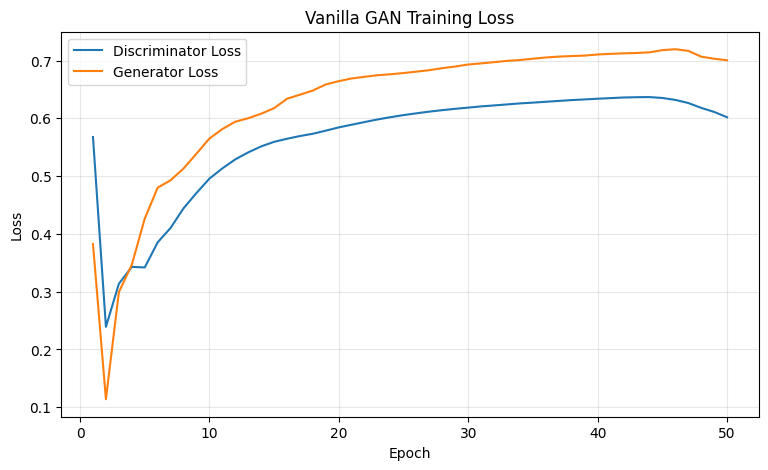

In [26]:
epochs = np.arange(
    1,
    len(vanilla_d_losses) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    vanilla_d_losses,
    label="Discriminator Loss"
)

plt.plot(
    epochs,
    vanilla_g_losses,
    label="Generator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla GAN Training Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

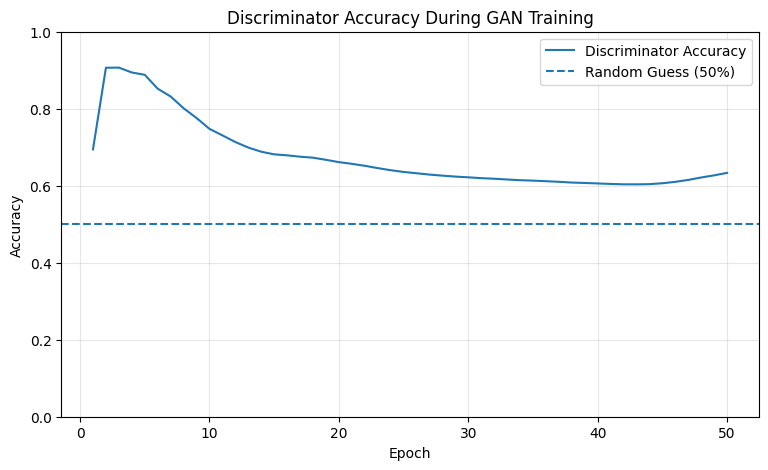

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    vanilla_d_accuracies,
    label="Discriminator Accuracy"
)

plt.axhline(
    y=0.5,
    linestyle="--",
    label="Random Guess (50%)"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Discriminator Accuracy During GAN Training")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [8]:
# Your code goes here
# 1.4

## 2. Open discussion questions

In [9]:
# Your argument goes here
# 2.1

In [10]:
# Your argument goes here
# 2.2

In [11]:
# Your argument goes here
# 2.3

In [12]:
# Your argument goes here
# 2.4

In [13]:
# Your argument goes here
# 2.5